# ExperimentGuard: A/B Testing & Retention Analysis
## Case Study: Cookie Cats Gate Placement Experiment (Level 30 vs Level 40)

**Author:** ZeeqRyz  
**Project:** Project 6 — ExperimentGuard  
**Primary Question:** Does moving the initial progression gate from Level 30 to Level 40 meaningfully increase seven-day retention (`retention_7`)?

## 1. Setup & Configuration
We load the frozen experiment protocol configuration from `configs/experiment.yaml` and verify the execution environment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from experimentguard.config import load_config
from experimentguard.data import load_and_validate_dataset
from experimentguard.decision import evaluate_decision
from experimentguard.effects import (
    calculate_retention_effect,
    run_secondary_and_sensitivity_analysis,
)
from experimentguard.integrity import check_integrity
from experimentguard.power import plan_power_scenarios, power_scenarios_to_dataframe

# Find repository root
root_dir = Path.cwd()
if (
    not (root_dir / "configs" / "experiment.yaml").is_file()
    and (root_dir.parent / "configs" / "experiment.yaml").is_file()
):
    root_dir = root_dir.parent

cfg_path = root_dir / "configs" / "experiment.yaml"
data_path = root_dir / "data" / "raw" / "cookie_cats.csv"
manifest_path = root_dir / "data" / "source_manifest.json"

cfg = load_config(cfg_path)
print(f"Loaded experiment: {cfg.experiment_id} (Protocol v{cfg.protocol_version})")
print(f"Control arm: {cfg.control}, Treatment arm: {cfg.treatment}")
print(
    f"Primary metric: {cfg.primary_metric}, Practical threshold: +{cfg.minimum_meaningful_effect_absolute * 100:.2f} pp"
)

Loaded experiment: cookie_cats_gate_placement (Protocol v1.0)
Control arm: gate_30, Treatment arm: gate_40
Primary metric: retention_7, Practical threshold: +0.50 pp


## 2. Data Ingestion & Quality Validation
We strictly validate the CSV schema, verify user uniqueness, and retain all assigned users (including zero-round players) according to intention-to-treat (ITT) principles.

In [2]:
df, val_report = load_and_validate_dataset(data_path, cfg.control, cfg.treatment)

print(f"Data validation passed: {val_report.is_valid}")
print(f"Total input rows: {val_report.input_rows:,}")
print(f"Unique users: {val_report.unique_users:,}")
print(f"Arm counts: {val_report.arm_counts}")
print(f"Zero-round users: {val_report.zero_rounds_count:,}")
print(f"Data SHA-256: {val_report.data_sha256}")

df.head()

Data validation passed: True
Total input rows: 90,189
Unique users: 90,189
Arm counts: {'gate_30': 44700, 'gate_40': 45489}
Zero-round users: 3,994
Data SHA-256: 5ab54d761fbddcd50de7b88e4eaf7837cba4569474f50c043a4d17ee342c46bd


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 3. Sample Ratio Mismatch (SRM) & Evidence Integrity
We evaluate whether the observed variant split matches the expected 50:50 allocation using an exact two-sided binomial test ($H_0: q_B = 0.50$, $\alpha_{\text{SRM}} = 0.001$).

In [3]:
integ_report = check_integrity(val_report, cfg, manifest_path=manifest_path)

print(f"SRM Test Status: {integ_report.srm_status.upper()}")
print(f"Observed Treatment Fraction: {integ_report.observed_treatment_fraction * 100:.2f}%")
print(
    f"SRM Two-Sided p-value: {integ_report.srm_pvalue:.6f} (Threshold: {integ_report.srm_threshold})"
)
print(f"Overall Quality Status: {integ_report.status.upper()}")
print("\nDocumented Limitations:")
for lim in integ_report.limitations:
    print(f" - {lim}")

SRM Test Status: PASS
Observed Treatment Fraction: 50.44%
SRM Two-Sided p-value: 0.008692 (Threshold: 0.001)
Overall Quality Status: PROVISIONAL

Documented Limitations:
 - Random assignment is source-reported but not independently verifiable via server logs.
 - Expected 50:50 allocation is assumed; SRM tested under assumed allocation.
 - Maturity evidence unknown: installation timestamps and cohort cutoffs are absent.
 - No user installation timestamps or geographic/device covariates available in public snapshot.
 - Original randomization mechanism is reported by source but not independently verifiable.
 - Maturity and follow-up window completeness cannot be proven without event logs.
 - Revenue and monetization outcomes are unavailable; gate movement impact on total in-app purchases cannot be directly inferred.


## 4. Primary Retention Effect Estimation & Decision Rules
We estimate the 7-day retention rates, Wilson confidence intervals for each arm, Newcombe difference interval for $(p_B - p_A)$, and the pooled two-proportion z-test.

In [4]:
primary_res = calculate_retention_effect(
    df=df,
    metric_col=cfg.primary_metric,
    control_arm=cfg.control,
    treatment_arm=cfg.treatment,
    alpha=cfg.alpha,
    method=cfg.confidence_method,
)

decision = evaluate_decision(
    integrity=integ_report,
    primary_effect=primary_res,
    d_min=cfg.minimum_meaningful_effect_absolute,
    alpha=cfg.alpha,
)

print(
    f"Control Rate (gate_30): {primary_res.rate_control * 100:.2f}% [{primary_res.rate_control_ci[0] * 100:.2f}%, {primary_res.rate_control_ci[1] * 100:.2f}%]"
)
print(
    f"Treatment Rate (gate_40): {primary_res.rate_treatment * 100:.2f}% [{primary_res.rate_treatment_ci[0] * 100:.2f}%, {primary_res.rate_treatment_ci[1] * 100:.2f}%]"
)
print(
    f"Effect (Treatment - Control): {primary_res.effect_percentage_points:+.2f} percentage points"
)
print(
    f"95% Newcombe CI: [{primary_res.ci_absolute[0] * 100:+.2f} pp, {primary_res.ci_absolute[1] * 100:+.2f} pp]"
)
print(f"p-value: {primary_res.pvalue:.4e} ({primary_res.test_method})")
print(f"\nDeterministic Decision: {decision.status.upper()}")
print(f"Explanation: {decision.explanation}")

Control Rate (gate_30): 19.02% [18.66%, 19.39%]
Treatment Rate (gate_40): 18.20% [17.85%, 18.56%]
Effect (Treatment - Control): -0.82 percentage points
95% Newcombe CI: [-1.33 pp, -0.31 pp]
p-value: 1.5542e-03 (z_test)

Deterministic Decision: NOT_SUPPORTED
Explanation: Evidence does not support rollout: 95% CI upper bound (-0.0031) is strictly below 0.0, indicating statistically reliable negative impact (harm).


### Primary Visualizations
We visualize the arm retention rates and the effect estimate relative to zero and the practical threshold.

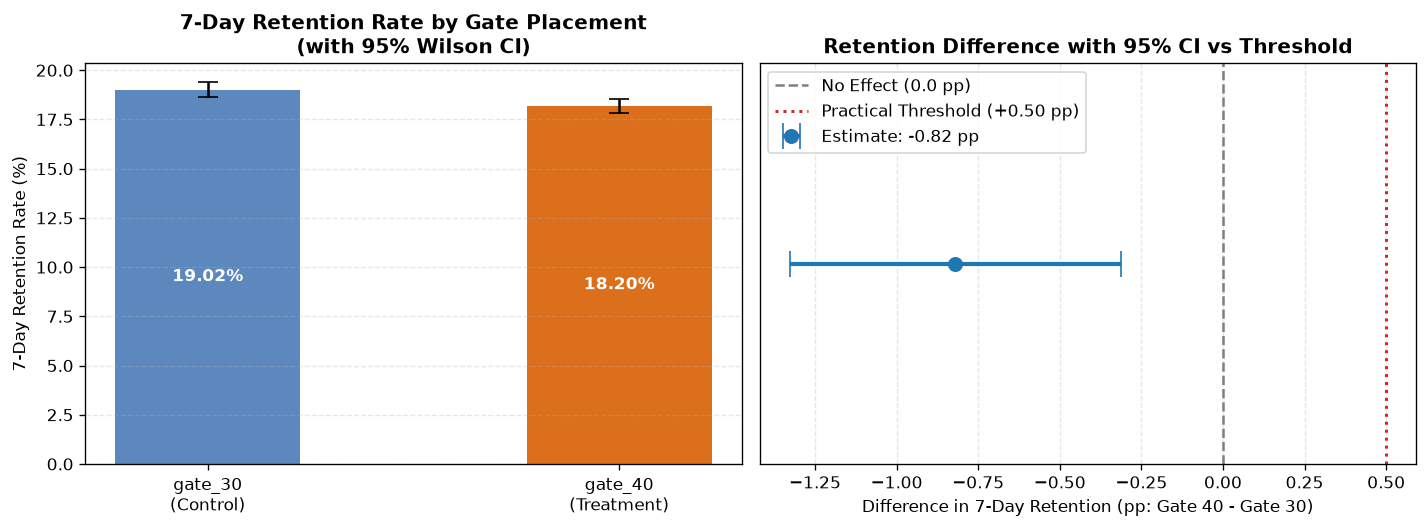

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=120)

# 1. Arm Rates
arms = [f"{cfg.control}\n(Control)", f"{cfg.treatment}\n(Treatment)"]
rates = [primary_res.rate_control * 100, primary_res.rate_treatment * 100]
err_low = [
    (primary_res.rate_control - primary_res.rate_control_ci[0]) * 100,
    (primary_res.rate_treatment - primary_res.rate_treatment_ci[0]) * 100,
]
err_high = [
    (primary_res.rate_control_ci[1] - primary_res.rate_control) * 100,
    (primary_res.rate_treatment_ci[1] - primary_res.rate_treatment) * 100,
]

bars = ax1.bar(
    arms,
    rates,
    yerr=[err_low, err_high],
    capsize=6,
    color=["#4A7BB7", "#D95F02"],
    width=0.45,
    alpha=0.9,
)
ax1.set_ylabel("7-Day Retention Rate (%)")
ax1.set_title("7-Day Retention Rate by Gate Placement\n(with 95% Wilson CI)", fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.3)
for b, r in zip(bars, rates):
    ax1.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() / 2,
        f"{r:.2f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )

# 2. Difference CI vs Practical Threshold
diff_pp = primary_res.effect_percentage_points
ci_l_pp = primary_res.ci_absolute[0] * 100
ci_h_pp = primary_res.ci_absolute[1] * 100
d_min_pp = cfg.minimum_meaningful_effect_absolute * 100

ax2.errorbar(
    [diff_pp],
    [0],
    xerr=[[diff_pp - ci_l_pp], [ci_h_pp - diff_pp]],
    fmt="o",
    color="#1F77B4",
    elinewidth=2.5,
    capsize=8,
    markersize=8,
    label=f"Estimate: {diff_pp:+.2f} pp",
)
ax2.axvline(0.0, color="#7F7F7F", linestyle="--", linewidth=1.5, label="No Effect (0.0 pp)")
ax2.axvline(
    d_min_pp,
    color="#D62728",
    linestyle=":",
    linewidth=1.8,
    label=f"Practical Threshold (+{d_min_pp:.2f} pp)",
)
ax2.set_yticks([])
ax2.set_xlabel("Difference in 7-Day Retention (pp: Gate 40 - Gate 30)")
ax2.set_title("Retention Difference with 95% CI vs Threshold", fontweight="bold")
ax2.legend(loc="upper left")
ax2.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Secondary & Sensitivity Analyses
We investigate 1-day retention (`retention_1`), gameplay engagement (`sum_gamerounds`), apply Holm-Bonferroni multiple testing correction across the exploratory family, and run outlier & bootstrap sensitivity checks.

In [6]:
sec_res = run_secondary_and_sensitivity_analysis(
    df=df,
    control_arm=cfg.control,
    treatment_arm=cfg.treatment,
    alpha=cfg.alpha,
    method=cfg.confidence_method,
    seed=cfg.seed,
    bootstrap_replicates=cfg.bootstrap_replicates,
)

print("=== Secondary Retention (Day 1) ===")
print(f"Control (gate_30): {sec_res.day1_retention.rate_control * 100:.2f}%")
print(f"Treatment (gate_40): {sec_res.day1_retention.rate_treatment * 100:.2f}%")
print(
    f"Effect: {sec_res.day1_retention.effect_percentage_points:+.2f} pp (Raw p={sec_res.day1_retention.pvalue:.4f}, Holm p={sec_res.holm_family_pvalues['retention_1_holm']:.4f})"
)

print("\n=== Engagement (sum_gamerounds) ===")
print(
    f"Control Mean: {sec_res.engagement.control_summary.mean:.2f} rounds (Median={sec_res.engagement.control_summary.median:.0f}, Max={sec_res.engagement.control_summary.max:.0f})"
)
print(
    f"Treatment Mean: {sec_res.engagement.treatment_summary.mean:.2f} rounds (Median={sec_res.engagement.treatment_summary.median:.0f}, Max={sec_res.engagement.treatment_summary.max:.0f})"
)
print(
    f"Welch t-test p-value: {sec_res.engagement.welch_pvalue:.4f} (Holm p={sec_res.holm_family_pvalues['sum_gamerounds_holm']:.4f})"
)

print("\n=== Outlier & Bootstrap Sensitivity ===")
print(
    f"P99 Winsorized Capped Difference: {sec_res.outlier_sensitivity.capped_mean_diff:+.2f} rounds (Cap={sec_res.outlier_sensitivity.cap_value:.0f})"
)
print(
    f"Bootstrap 95% Percentile CI: [{sec_res.primary_bootstrap.bootstrap_ci_percentage_points[0]:+.2f} pp, {sec_res.primary_bootstrap.bootstrap_ci_percentage_points[1]:+.2f} pp]"
)

=== Secondary Retention (Day 1) ===
Control (gate_30): 44.82%
Treatment (gate_40): 44.23%
Effect: -0.59 pp (Raw p=0.0744, Holm p=0.1488)

=== Engagement (sum_gamerounds) ===
Control Mean: 52.46 rounds (Median=17, Max=49854)
Treatment Mean: 51.30 rounds (Median=16, Max=2640)
Welch t-test p-value: 0.3759 (Holm p=0.3759)

=== Outlier & Bootstrap Sensitivity ===
P99 Winsorized Capped Difference: -0.28 rounds (Cap=493)
Bootstrap 95% Percentile CI: [-1.34 pp, -0.31 pp]


## 6. Prospective Sample Size & Power Planning
We plan sample size requirements for future experiments under various Minimum Detectable Effect (MDE) scenarios.

In [7]:
power_scenarios = plan_power_scenarios(
    baseline_rate=cfg.planning.baseline_rate,
    mde_list=cfg.planning.mde_absolute,
    alpha=cfg.alpha,
    target_power=cfg.planning.target_power,
    expected_treatment_fraction=cfg.expected_treatment_fraction,
)

df_power = power_scenarios_to_dataframe(power_scenarios)
df_power[
    [
        "scenario_id",
        "baseline_rate",
        "mde_percentage_points",
        "required_n_control",
        "required_n_treatment",
        "required_n_total",
        "achieved_power",
    ]
]

,scenario_id,baseline_rate,mde_percentage_points,required_n_control,required_n_treatment,required_n_total,achieved_power
0,mde_0.25pp,0.2,0.25,403738,403738,807476,0.800000
1,mde_0.50pp,0.2,0.50,101400,101400,202800,0.800000
2,mde_1.00pp,0.2,1.00,25580,25580,51160,0.800001


## 7. Conclusions & Executive Recommendation
- **Finding:** Moving the gate to Level 40 produced a statistically significant reduction in 7-day player retention (-0.82 pp, $p=0.0016$).
- **Decision:** `NOT_SUPPORTED` with evidence consistent with a retention decrease (provisional evidence grade based on retrospective snapshot).
- **Recommendation:** Keep the initial progression gate at **Level 30**.